# Experiment 9 - Model 4: Fine-tuning MuRIL (Transformer)

This notebook continues `Experiment_9.ipynb`. The classical TF-IDF models reached about **75% accuracy**.
Here we fine-tune **MuRIL** (*Multilingual Representations for Indian Languages*, by Google), a BERT model
pretrained on 17 Indian languages **including Romanized (transliterated) Hindi**, which makes it well suited to Hinglish.

**Hardware:** runs on a GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*), Apple Silicon (MPS), or CPU (slow).

## 1. Setup and hyperparameters

In [1]:
# On Colab, first run: !pip install transformers
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")
RESULTS = "results"

# ---- Hyperparameters ----
MODEL_NAME    = "google/muril-base-cased"
MAX_LEN       = 64      # max tokens per post
BATCH_SIZE    = 32
LEARNING_RATE = 5e-5
EPOCHS        = 6
WARMUP_RATIO  = 0.1     # first 10% of steps: learning rate rises from 0 to LEARNING_RATE
WEIGHT_DECAY  = 0.01
SEED          = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)

Device: mps


## 2. Data
Same train / test files as the main notebook. We hold out **10% of the training set as a validation set**
to pick the best epoch, so the test set stays untouched until the final evaluation.

Preprocessing is lighter than for TF-IDF: transformers use their own **WordPiece tokenizer** and benefit from
context words, so we only drop missing/duplicate rows and remove URLs/mentions - no stop-word removal.

In [2]:
import re
def light_clean(t):
    t = re.sub(r"http\S+|www\.\S+|@\w+", " ", str(t))
    return re.sub(r"\s+", " ", t).strip()

train_df = pd.read_csv("data/Train_data_MC-Hinglish1.0.csv").dropna().drop_duplicates()
test_df  = pd.read_csv("data/Test_data_MC-Hinglish1.0.csv")
train_df["text"] = train_df["tweets"].apply(light_clean)
test_df["text"]  = test_df["tweets"].apply(light_clean)

labels = sorted(train_df["cyberbullying_type"].unique())
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}

tr_df, val_df = train_test_split(train_df, test_size=0.1, stratify=train_df["cyberbullying_type"], random_state=SEED)
print(f"Train: {len(tr_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")
print("Classes:", labels)

Train: 6652 | Validation: 740 | Test: 1000
Classes: ['abusive', 'age', 'gender', 'mockery', 'not_cyberbullying', 'offensive', 'religion']


## 3. Tokenization

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = train_df["text"].iloc[3]
print("Text  :", example)
print("Tokens:", tokenizer.tokenize(example))

lens = [len(tokenizer.tokenize(t)) for t in train_df["text"]]
print(f"\nToken length - mean: {np.mean(lens):.1f}, 95th percentile: {np.percentile(lens, 95):.0f}, max: {max(lens)}")
print(f"Posts longer than MAX_LEN={MAX_LEN}: {np.mean(np.array(lens) > MAX_LEN - 2) * 100:.1f}% (these get truncated)")

def encode(df, shuffle):
    enc = tokenizer(list(df["text"]), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
    y = torch.tensor(df["cyberbullying_type"].map(label2id).values)
    return DataLoader(TensorDataset(enc["input_ids"], enc["attention_mask"], y), batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = encode(tr_df, shuffle=True)
val_loader   = encode(val_df, shuffle=False)
test_loader  = encode(test_df, shuffle=False)

Text  : Didi show off krri h "Left hand rule"
Tokens: ['Did', '##i', 'show', 'off', 'k', '##rri', 'h', '"', 'Left', 'hand', 'rule', '"']

Token length - mean: 26.1, 95th percentile: 49, max: 1670
Posts longer than MAX_LEN=64: 3.7% (these get truncated)


## 4. Model and training
Pretrained MuRIL + a new classification layer (7 outputs). The whole network is fine-tuned with the
**AdamW** optimizer and a **linear learning-rate schedule with warm-up**. After every epoch we check the
validation set and keep the weights from the best epoch.

In [4]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(labels), id2label=id2label, label2id=label2id).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)

def predict_loader(loader):
    model.eval()
    preds, losses = [], []
    with torch.no_grad():
        for ids, mask, y in loader:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            out = model(input_ids=ids, attention_mask=mask, labels=y)
            losses.append(out.loss.item())
            preds.extend(out.logits.argmax(-1).cpu().tolist())
    return np.array(preds), float(np.mean(losses))

print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M | steps per epoch: {len(train_loader)}")

Parameters: 238M | steps per epoch: 208


In [5]:
history, best_f1, best_state = [], -1, None
val_true = val_df["cyberbullying_type"].map(label2id).values

for epoch in range(1, EPOCHS + 1):
    model.train(); start = time.time(); train_losses = []
    for ids, mask, y in train_loader:
        ids, mask, y = ids.to(device), mask.to(device), y.to(device)
        loss = model(input_ids=ids, attention_mask=mask, labels=y).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); scheduler.step(); optimizer.zero_grad()
        train_losses.append(loss.item())

    val_pred, val_loss = predict_loader(val_loader)
    val_acc = accuracy_score(val_true, val_pred)
    val_f1  = f1_score(val_true, val_pred, average="macro")
    history.append({"epoch": epoch, "train_loss": np.mean(train_losses), "val_loss": val_loss,
                    "val_accuracy": val_acc, "val_macro_f1": val_f1})
    print(f"Epoch {epoch}/{EPOCHS} | train loss {np.mean(train_losses):.4f} | val loss {val_loss:.4f} "
          f"| val acc {val_acc:.4f} | val F1 {val_f1:.4f} | {time.time() - start:.0f}s")

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
best_epoch = max(history, key=lambda h: h["val_macro_f1"])["epoch"]
print(f"\nBest epoch: {best_epoch} (val macro F1 = {best_f1:.4f})")

Epoch 1/6 | train loss 1.8478 | val loss 1.6301 | val acc 0.4405 | val F1 0.3728 | 122s
Epoch 2/6 | train loss 1.2707 | val loss 1.0387 | val acc 0.6716 | val F1 0.6251 | 134s
Epoch 3/6 | train loss 0.8299 | val loss 0.8152 | val acc 0.7365 | val F1 0.7066 | 142s
Epoch 4/6 | train loss 0.6077 | val loss 0.7124 | val acc 0.7716 | val F1 0.7555 | 143s
Epoch 5/6 | train loss 0.4746 | val loss 0.7095 | val acc 0.7730 | val F1 0.7612 | 144s
Epoch 6/6 | train loss 0.3889 | val loss 0.7132 | val acc 0.7757 | val F1 0.7667 | 145s

Best epoch: 6 (val macro F1 = 0.7667)


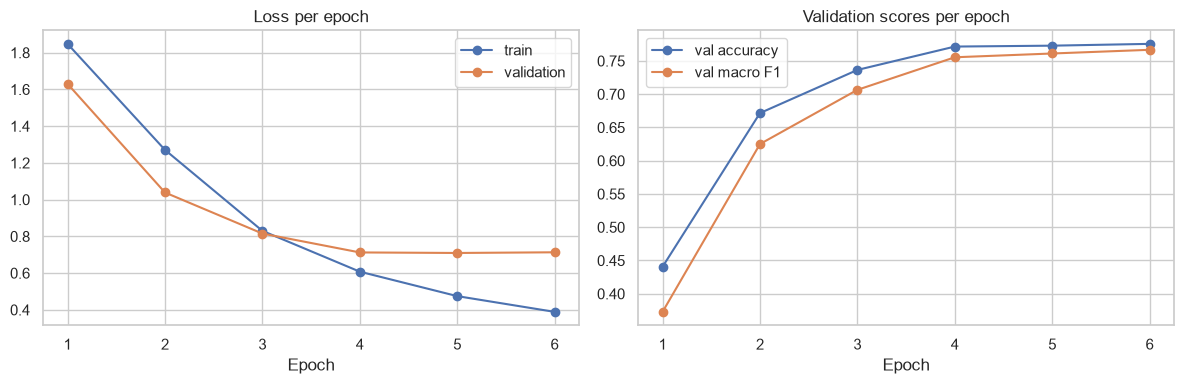

In [6]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["epoch"], hist["train_loss"], "o-", label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], "o-", label="validation")
axes[0].set_title("Loss per epoch"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(hist["epoch"], hist["val_accuracy"], "o-", label="val accuracy")
axes[1].plot(hist["epoch"], hist["val_macro_f1"], "o-", label="val macro F1")
axes[1].set_title("Validation scores per epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend()
for ax in axes: ax.set_xticks(hist["epoch"])
plt.tight_layout()
plt.savefig(f"{RESULTS}/muril_training_curves.png", dpi=150)
plt.show()

## 5. Evaluation on the test set

In [7]:
test_true = test_df["cyberbullying_type"].map(label2id).values
test_pred, _ = predict_loader(test_loader)

muril_row = {
    "Model": "MuRIL (fine-tuned)",
    "Accuracy":  accuracy_score(test_true, test_pred),
    "Precision": precision_score(test_true, test_pred, average="macro"),
    "Recall":    recall_score(test_true, test_pred, average="macro"),
    "Macro F1":  f1_score(test_true, test_pred, average="macro"),
}
print(classification_report(test_true, test_pred, target_names=labels, digits=3))

                   precision    recall  f1-score   support

          abusive      0.637     0.486     0.552       148
              age      0.868     0.915     0.891       129
           gender      0.708     0.723     0.716       141
          mockery      0.352     0.441     0.392       127
not_cyberbullying      0.834     0.780     0.806       200
        offensive      0.424     0.427     0.426       124
         religion      0.838     0.870     0.854       131

         accuracy                          0.671      1000
        macro avg      0.666     0.663     0.662      1000
     weighted avg      0.680     0.671     0.673      1000



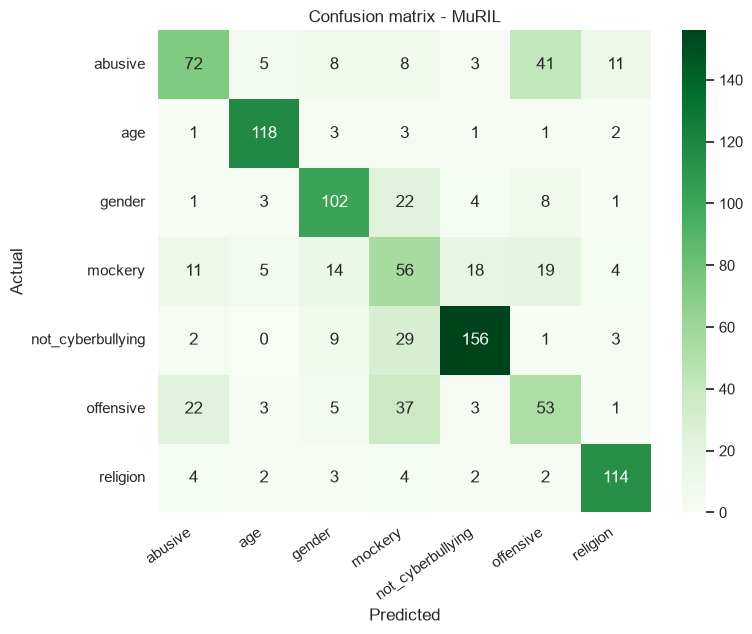

In [8]:
cm = confusion_matrix(test_true, test_pred)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=labels, yticklabels=labels)
plt.title("Confusion matrix - MuRIL")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(f"{RESULTS}/muril_confusion_matrix.png", dpi=150)
plt.show()

### Comparison with the classical models

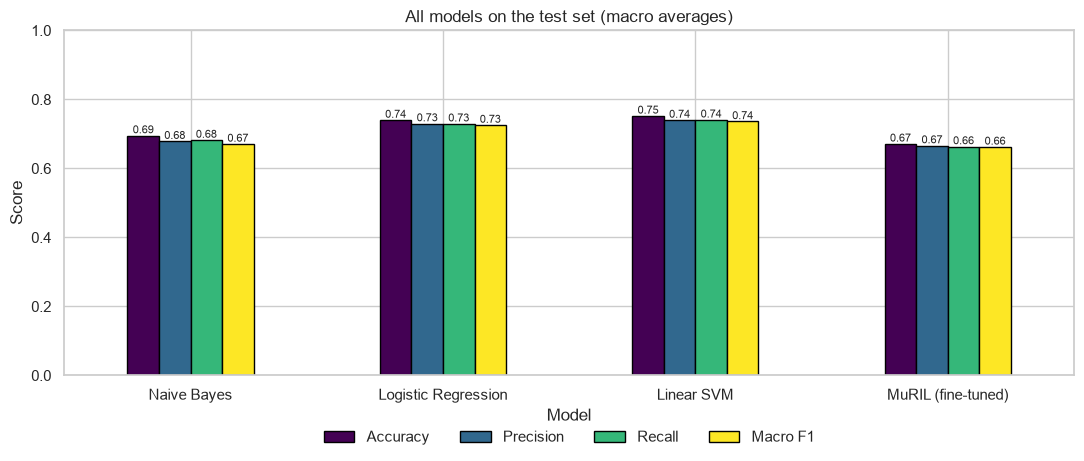

,Accuracy,Precision,Recall,Macro F1
Model,,,,
Naive Bayes,0.695,0.6786,0.6820,0.6706
Logistic Regression,0.740,0.7298,0.7293,0.7255
Linear SVM,0.752,0.7401,0.7407,0.7360
MuRIL (fine-tuned),0.671,0.6660,0.6633,0.6622


In [9]:
classical = pd.read_csv(f"{RESULTS}/model_comparison.csv")   # written by Experiment_9.ipynb
all_results = pd.concat([classical, pd.DataFrame([muril_row])]).set_index("Model").round(4)
all_results.to_csv(f"{RESULTS}/all_models_comparison.csv")

ax = all_results.plot(kind="bar", figsize=(11, 4.8), rot=0, colormap="viridis", edgecolor="black")
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("All models on the test set (macro averages)")
ax.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.12), frameon=False)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig(f"{RESULTS}/all_models_comparison.png", dpi=150)
plt.show()
all_results

### Try it on new posts

In [10]:
def predict(texts):
    model.eval()
    enc = tokenizer([light_clean(t) for t in texts], padding=True, truncation=True,
                    max_length=MAX_LEN, return_tensors="pt").to(device)
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits, dim=-1).cpu()
    conf, idx = probs.max(-1)
    return pd.DataFrame({"post": texts, "predicted_class": [id2label[i] for i in idx.tolist()],
                         "confidence": conf.numpy().round(3)})

predict([
    "Aaj ka match bahut accha tha, great game guys!",
    "Ladkiyon ko kitchen mein hi rehna chahiye",
    "Buddhe ho gaye ho ab retire ho jao uncle",
    "Wah kya baat hai, tumse zyada smart toh mera phone hai",
    "Tu bilkul pagal hai saale",
])

,post,predicted_class,confidence
0,"Aaj ka match bahut accha tha, great game guys!",not_cyberbullying,0.972
1,Ladkiyon ko kitchen mein hi rehna chahiye,gender,0.727
2,Buddhe ho gaye ho ab retire ho jao uncle,age,0.943
3,"Wah kya baat hai, tumse zyada smart toh mera p...",mockery,0.723
4,Tu bilkul pagal hai saale,offensive,0.424


## Conclusion
- **First try** (learning rate 3e-5, 3 epochs) **underfit**: 55.4% test accuracy, with validation still rising.
- **Raising the learning rate to 5e-5 and training for 6 epochs** gave **67.1% test accuracy and 0.662 macro F1**, and validation levelled off after epoch 4.
- The **TF-IDF + Linear SVM** model (75.2%) still wins on this small, keyword-driven dataset, and it trains in seconds instead of about 14 minutes.
- MuRIL does well on `age`, `religion` and `not_cyberbullying`; like the SVM, it struggles with `mockery` and `offensive`.